<img src="https://drive.google.com/uc?export=view&id=1WNLKH10YpQNNk9eeRIyYLwGkxNbNp-Mm" width="100%">

# **Modelamiento y Evaluación**
---
Dando continuidad al desarrollo del proyecto en esta fase, realizaremos la implementación y evaluación de un modelo de Machine Learning para el analisis de sentimiento sobre noticias financieras, con el fin de cumplir con las actividades propuestas en el cronograma correspondiente a la semana 6.

## **Integrantes del equipo de trabajo**
---

1. **Jhon Anderson Bermudez Hurtado**
2. **Natalia Patricia Remolina Rodriguez**
3. **Juan Carlos Andrade Unigarro**

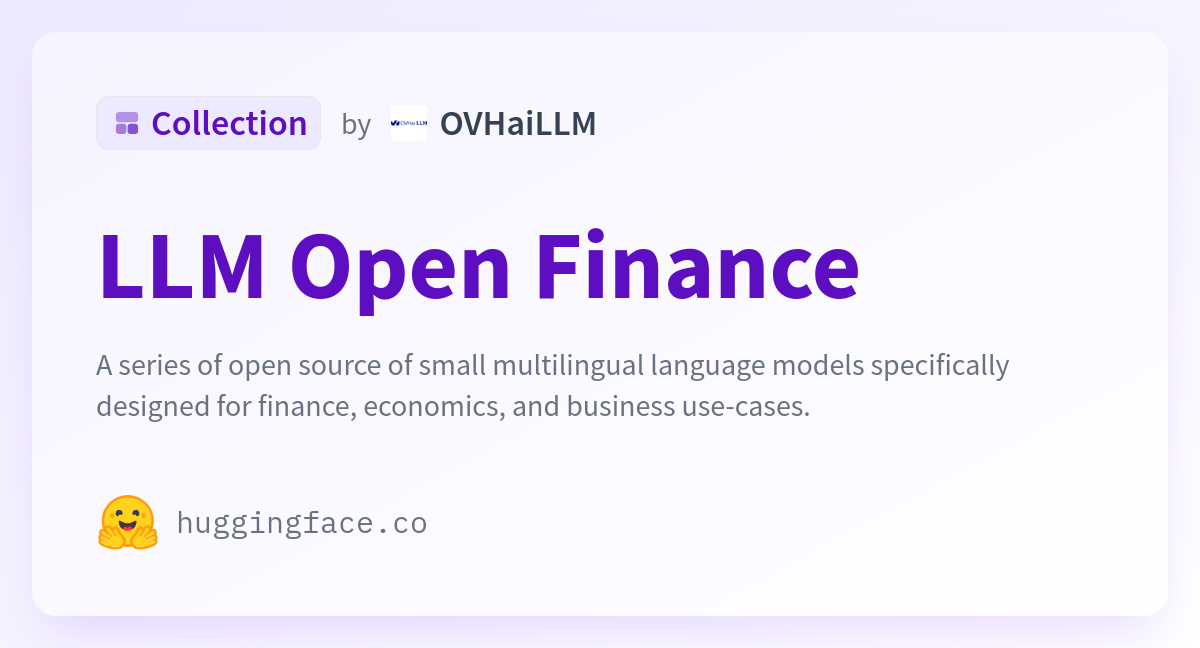

A continuación se muestra el diagrama de Gantt propuesto para el proyecto en el cual se indican las activades que se van a realizar en la semana 6.

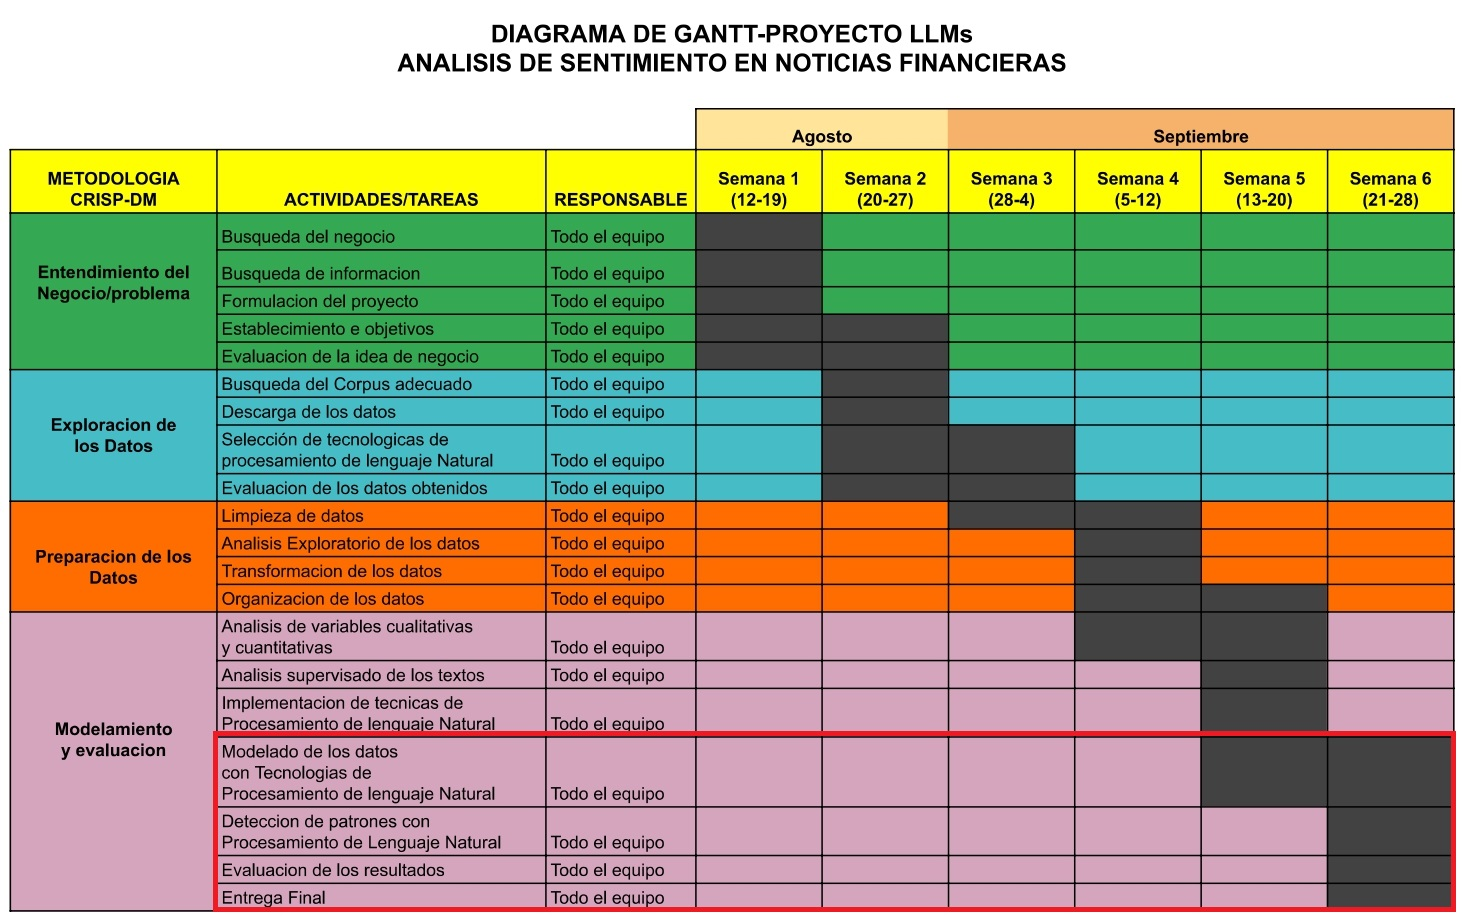

Tras haber explorado y seleccionado el método de representación de textos más adecuado para capturar la esencia de las reseñas, emplearemos esta representación como el principal insumo para entrenar un modelo de aprendizaje automático.

Este modelo será diseñado específicamente para discernir y aprender los patrones subyacentes que vinculan las características del texto de las reseñas con la variable objetivo `label`. Nuestra meta es construir un modelo robusto y preciso que pueda predecir con confianza la valoración de una noticia economica basándose en el análisis del texto de sus reseñas.

## **Cargamos los paquetes necesarios**


In [ ]:
#Instalación de Gensim
!pip install gensim


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 27.8/27.8 MB 51.7 MB/s eta 0:00:00


In [ ]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.base import BaseEstimator
from gensim.models import Word2Vec

from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier

from sklearn.pipeline import Pipeline
from sklearn.model_selection import train_test_split, GridSearchCV

from sklearn.metrics import classification_report
from sklearn.metrics import confusion_matrix

## **0. Conjunto de datos**


En la etapa anterior, seleccionamos el método **TF-IDF (Term Frequency-Inverse Document Frequency)** como nuestra técnica de representación de textos. No obstante, con fines académicos exploraremos igualmente el uso de **Word2Vec**, método que resultó tener un desempeño equivalente.

Es importante resaltar que, si bien empleamos una configuración estándar para el análisis inicial, es fundamental reconocer que ambos métodos poseen hiperparámetros que influyen significativamente en su desempeño y, por ende, en la calidad de nuestro modelo. En esta fase, optimizaremos estos hiperparámetros.

Para ello, volveremos a cargar el texto preprocesado y lo utilizaremos como insumo principal. Ajustar parámetros como la frecuencia mínima de documentos, el tamaño del vocabulario y los esquemas de ponderación nos permitirán afinar la representación de los textos y potenciar la capacidad del modelo para identificar patrones relevantes.

El conjunto de datos esta disponible desde Github por medio de este enlace: https://github.com/JhonAnderson44/financial_sentiment_es_prepared usaremos un codigo en Colab para importar el dataset, el cual se mostrará en la siguiente sección

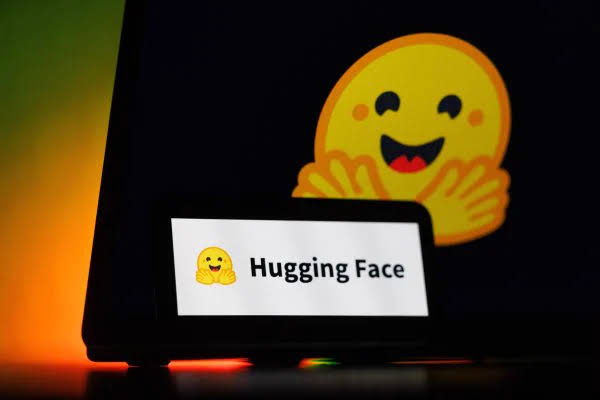

In [ ]:
#Cargue de conjunto de datos correcto desde Github
data_path ="https://raw.githubusercontent.com/JhonAnderson44/financial_sentiment_es_prepared/refs/heads/main/financial_sentiment_es_prepared.csv"
data = pd.read_csv(data_path)
data.head()

,sentence_original,sentence_clean,label,source,language,encoding_flag
0,- Isdin abrirá un centro logístico de 22.000 m...,isdin abrir centro logístico num metro bunzl a...,positive,expansion_empresas,es,True
1,MiiN Cosmetics dispara los ingresos y pisa el ...,miin cosmetics disparar ingreso pisa acelerado...,positive,expansion_empresas,es,False
2,La subida del volumen de negocio coincidió con...,subida volumen negocio coincidir apertura num ...,positive,expansion_empresas,es,True
3,La compańía barcelonesa entró el ańo pasado en...,compańía barcelonesa entrar ańo grecia firmar ...,neutral,expansion_empresas,es,True
4,MiiN también abrió en 2025 un centro logístico...,miin abrir num centro logístico num metro cuad...,positive,expansion_empresas,es,True


## **1. Tipo de Modelamiento**
---

Una etapa fundamental en el modelado es la definición precisa de la tarea que deseamos realizar. Para ello, es esencial determinar si contamos con una variable objetivo. En ausencia de una variable objetivo, recurriremos a técnicas de aprendizaje no supervisado, como el agrupamiento (clustering) o el análisis de tópicos. Estas técnicas nos permitirán descubrir patrones y estructuras ocultas en los datos sin necesidad de una guía predefinida.

Por otro lado, si disponemos de una variable objetivo, es crucial analizar su naturaleza para determinar si es continua o categórica. Esta distinción es fundamental, ya que nos permitirá establecer si nos enfrentamos a un problema de regresión o clasificación. En un problema de regresión, la variable objetivo es continua, lo que implica predecir un valor numérico. Por ejemplo, predecir el precio de una vivienda en función de sus características. En cambio, en un problema de clasificación, la variable objetivo es categórica, lo que significa predecir una etiqueta o clase. Por ejemplo, clasificar correos electrónicos como "spam" o "no spam".

<center>
  <img src="https://drive.google.com/uc?export=view&id=1hD2CJmggb3y2Dpvkcui168OXDmxppNJ8" width="100%" alt="Mapa ML">
</center>

Recordemos que para el presente análisis contamos con la variable objetivo `label`.

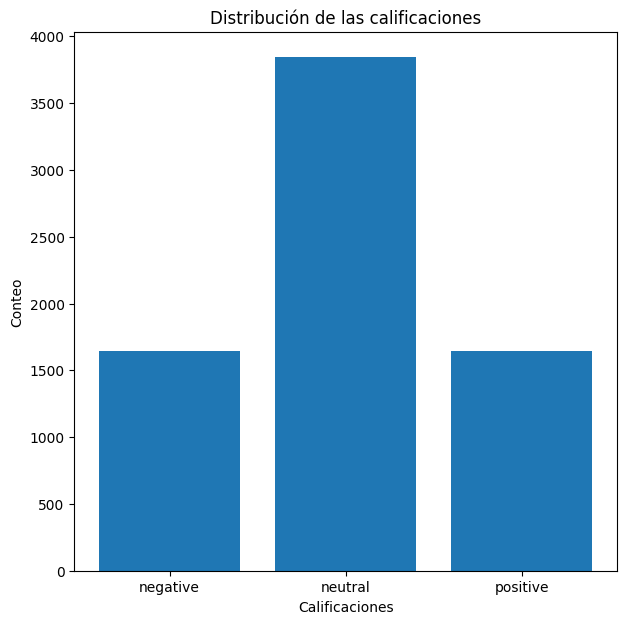

In [ ]:
variable_obj = data['label']
etiquetas_obj, conteo_etiquetas = np.unique(variable_obj,return_counts=True)

fig, (ax1) = plt.subplots(1, 1, figsize=(7, 7))

ax1.bar(etiquetas_obj, conteo_etiquetas)
ax1.set_title('Distribución de las calificaciones')

ax1.set_xlabel('Calificaciones')
ax1.set_ylabel('Conteo')

plt.show()

La gráfica representa una variable categórica, evidenciado por la representación de valores de tres etiquetas (positive, neutral, negative) en barras separadas, indicando categorías específicas, donde el valor más alto representa clasificación con mayor numero de etiquetas asociadas. La elección de la gráfica de barras refuerza esta clasificación, siendo ideal para visualizar la distribución y frecuencia de las categorías.

Debido a la naturaleza categórica de la variable objetivo, la tarea se identifica como un problema de clasificación. Esto implica que el modelo deberá aprender a asignar una categoría a cada instancia. Se explorarán diversos algoritmos de clasificación y se seleccionará el modelo con mejor desempeño.

## **2. Implementación del modelo**
---


### **2.1. Particionamiento de los datos**
---

Una etapa fundamental previa al modelado es el diseño de un experimento riguroso que incluya una particion de datos adecuado. Esto asegura una evaluación objetiva e imparcial del modelo, evitando sesgos y permitiendo una mejor comprensión de su rendimiento. Si bien en la etapa anterior empleamos varios conjuntos de retención ("*hold-out*") para evaluar el método de representación de textos, en esta fase adoptaremos un enfoque híbrido y exhaustivo para garantizar una evaluación robusta y una búsqueda óptima de hiperparámetros.

Específicamente, volveremos a utilizar la estrategia "*hold-out*" para obtener el conjunto de prueba final, el cual permanecerá sin modificaciones durante todo el proceso. No obstante, a diferencia del trabajo anterior, reemplazaremos el conjunto de ajuste por el método de validación cruzada **K-fold**. Esta técnica consiste en dividir el conjunto de entrenamiento en $K$ subconjuntos o "*folds*" de igual tamaño. Luego, se entrenan y evalúan $K$ modelos, cada uno utilizando $K-1$ folds para entrenamiento y el fold restante para validación. Esto nos proporciona $K$ estimaciones del rendimiento del modelo, las cuales se promedian para obtener una métrica más confiable y menos susceptible a la variabilidad del conjunto de entrenamiento.

La combinación de "*hold-out*" para el conjunto de prueba y *K-fold* para el conjunto de ajuste nos permite evaluar el modelo final en datos no vistos durante el entrenamiento y, al mismo tiempo, optimizar los hiperparámetros de manera más eficiente y robusta.

<center>
  <img src="https://drive.google.com/uc?export=view&id=1MUVMWM8qAM3LMUm337f_WjliRpDEKG_k" width="100%" alt="K-Folds">
</center>

Con el fin de asegurar la reproducibilidad de los resultados, utilizaremos la misma semilla aleatoria que se utilizo en la etapa anterior. Esto evita sesgos en la evaluación del método de representación.

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(data['sentence_clean'], data['label'], test_size=0.15, random_state=2402)

print(f'Numero de registros en train: {len(X_train)}')
print(f'Numero de registros en test: {len(X_test)}')

Numero de registros en train: 6056
Numero de registros en test: 1069


Una forma común y efectiva de verificar si el particionado de datos es adecuado consiste en analizar la distribución de la variable objetivo en los conjuntos de entrenamiento y prueba. Idealmente, ambas distribuciones deberían ser similares, lo que indica que el modelo será entrenado y evaluado en contextos semejantes. Si las distribuciones difieren significativamente, el modelo podría no generalizar bien a los datos de prueba, ya que estaría aprendiendo patrones específicos del conjunto de entrenamiento que no están presentes en el conjunto de prueba.


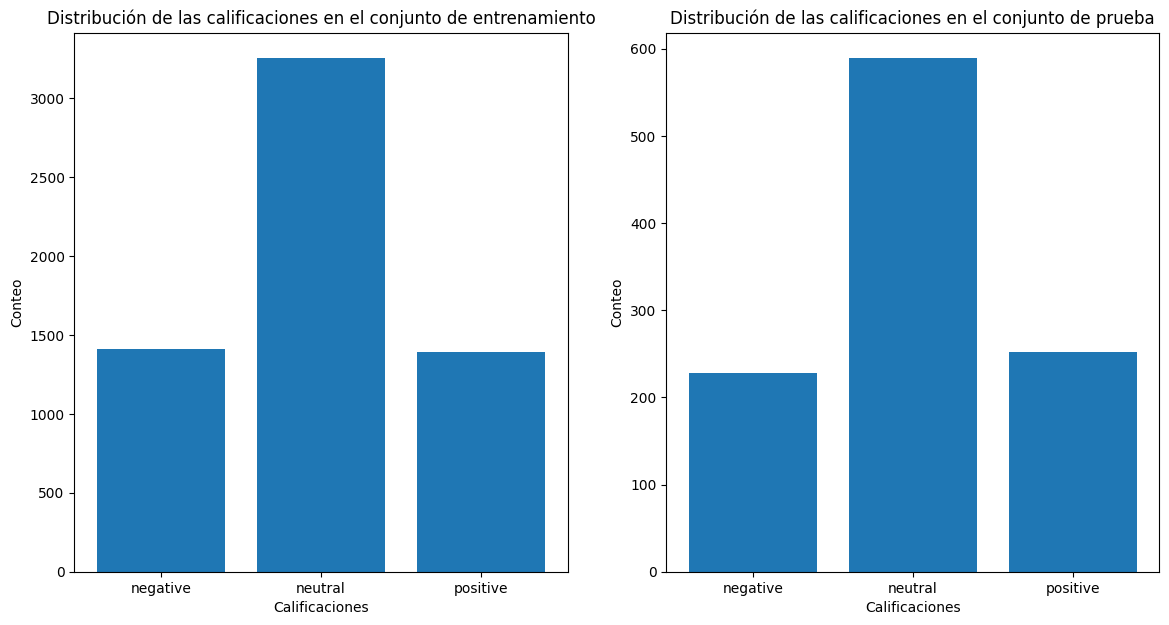

In [ ]:
fig, (ax1,ax2) = plt.subplots(1, 2, figsize=(14, 7))

variable_obj = y_train
etiquetas_obj, conteo_etiquetas = np.unique(variable_obj,return_counts=True)
ax1.bar(etiquetas_obj, conteo_etiquetas)
ax1.set_title('Distribución de las calificaciones en el conjunto de entrenamiento')
ax1.set_xlabel('Calificaciones')
ax1.set_ylabel('Conteo')

variable_obj = y_test
etiquetas_obj, conteo_etiquetas = np.unique(variable_obj,return_counts=True)
ax2.bar(etiquetas_obj, conteo_etiquetas)
ax2.set_title('Distribución de las calificaciones en el conjunto de prueba')
ax2.set_xlabel('Calificaciones')
ax2.set_ylabel('Conteo')

plt.show()

### **2.2. Entrenamiento del Modelo y Selección de Hiperparámetros**
---

Una vez diseñado el experimento y particionado el conjunto de datos de manera adecuada, el siguiente paso crucial es establecer los métodos de representación. En el caso de *TF-IDF*, su implementación resulta bastante sencilla debido a que se encuentra originalmente integrado en sklearn, no obstante en el caso de *Word2Vec* es necesario realizar un paso adicional.

#### **2.2.1. Word2Vec Wrapper**

Es fundamental recordar que **Word2Vec** no está implementado de forma nativa en scikit-learn (sklearn), lo que dificulta su integración directa con los modelos de esta librería. Para facilitar este proceso, es necesario crear una función *wrapper* o envoltorio. Esta función actúa como un puente, adaptando y reestructurando los objetos y salidas generadas por gensim para que sean compatibles y comprensibles para sklearn.

In [ ]:
class Word2VecWrapper(BaseEstimator):
    def __init__(self, max_features=100, epochs=10):
        self.max_features = max_features
        self.epochs = epochs
        self.model = None

    def fit(self, X, y=None):
        tokens = list(map(lambda doc: doc.split(), X))
        self.model = Word2Vec(sentences = tokens, vector_size = self.max_features, epochs = self.epochs, workers = -1)
        return self

    def transform(self, X):
        word2vect_embedding = []
        for i, doc in enumerate(X):
          doc_tokens = doc.split()
          vect = np.zeros(self.max_features)
          for token in doc_tokens:
            if token in self.model.wv.key_to_index:
              vect += self.model.wv[token]

          word2vect_embedding.append(vect)
        return np.array(word2vect_embedding)

Teniendo adaptado nuestros métodos de representación, debemos seleccionar los modelos de aprendizaje. Dado que nos enfrentamos a un problema de clasificación, exploraremos tres opciones que abarcan diferentes enfoques y capacidades:

1.  **Regresión Logística:** Este modelo, a pesar de su simplicidad, es una excelente opción inicial para determinar si el problema es linealmente separable. Su interpretabilidad nos permite comprender qué características son más relevantes para la clasificación.
2.  **Máquinas de Soporte Vectorial (SVM):** En caso de que la regresión logística no ofrezca resultados satisfactorios debido a la no linealidad del problema, las SVM nos permiten explorar soluciones más complejas. Mediante el uso de kernels, como el RBF (Radial Basis Function), podemos mapear los datos a un espacio de mayor dimensión donde las clases sean linealmente separables.
3. **Bosques Aleatorios (Random Forests):** Los bosques aleatorios son una alternativa popular y robusta, especialmente para datos tabulares como la representación extraída por TF-IDF. Su capacidad para manejar datos de alta dimensionalidad y su menor susceptibilidad al sobreajuste los convierten en una opción atractiva para este tipo de problemas.

La evaluación de estos tres modelos nos permitirá determinar cuál de ellos se adapta mejor a nuestros datos y objetivos, considerando tanto su rendimiento predictivo como su interpretabilidad y capacidad para generalizar a datos no vistos.

Por otra parte, como se observa en la distribución de la variable objetivo, existe un desbalanceo significativo entre las clases, lo que podría afectar el rendimiento del modelo al favorecer la clase mayoritaria. Para mitigar este problema, se ha configurado el parámetro `class_weight = "balanced"` en todos los modelos utilizados. Esta estrategia ajusta los pesos de cada clase de forma inversamente proporcional a su frecuencia, otorgando mayor importancia a las clases minoritarias durante el entrenamiento. Al hacerlo, se reduce el efecto del desbalanceo y se busca que el modelo aprenda a predecir de manera más equitativa todas las clases, mejorando su capacidad de generalización y evitando un sesgo hacia la clase dominante.

In [ ]:
#Pipeline regresión logistica - TF-IDF
pipeline_lr_TFIDF = Pipeline([('vectorizer', TfidfVectorizer()),
                              ('classifier', LogisticRegression(class_weight="balanced"))])

#Pipeline SVM  - TF-IDF
pipeline_svm_TFIDF = Pipeline([('vectorizer', TfidfVectorizer()),
                               ('classifier', SVC(kernel='rbf', class_weight="balanced", max_iter=50))])

#Pipeline random forest  - TF-IDF
pipeline_rf_TFIDF = Pipeline([('vectorizer', TfidfVectorizer()),
                        ('classifier', RandomForestClassifier(class_weight="balanced", max_samples= 100))])

#Pipeline regresión logistica - Word2Vec
pipeline_lr_W2V = Pipeline([('vectorizer', Word2VecWrapper()),
                        ('classifier', LogisticRegression(class_weight="balanced"))])

#Pipeline SVM - Word2Vec
pipeline_svm_W2V = Pipeline([('vectorizer', Word2VecWrapper()),
                             ('classifier', SVC(kernel='rbf', class_weight="balanced", max_iter=50))])

#Pipeline random forest - Word2Vec
pipeline_rf_W2V = Pipeline([('vectorizer', Word2VecWrapper()),
                            ('classifier', RandomForestClassifier(class_weight="balanced", max_samples= 100))])

Una vez generado los flujos de trabajo "**pipelines**" es necesario establecer el espacio de hiperparámetros para cada uno. Recuerde que los hiperparámetros son factores que deben proporcionarse inicialmente al modelo y que pueden afectar considerablemente su desempeño. En la siguiente tabla encontrará los hiperparámetros identificados para cada modelo y su espacio de búsqueda.

Una vez generados los flujos de trabajo ("pipelines"), es fundamental definir el espacio de hiperparámetros para cada modelo. Recordemos que los hiperparámetros son parámetros que se configuran antes del entrenamiento y que pueden influir significativamente en el desempeño del modelo. La selección adecuada del espacio de búsqueda es crucial para encontrar la combinación óptima de hiperparámetros que maximice el rendimiento del modelo.

A continuación, se presenta una tabla con los hiperparámetros identificados para cada modelo y su correspondiente espacio de búsqueda. Es importante destacar que este espacio ha sido definido considerando el conocimiento previo sobre el problema en cuestión. Se han incluido valores que abarcan un rango amplio de posibilidades, permitiendo explorar diferentes configuraciones y evaluar su impacto en el rendimiento del modelo.

| Hiperparámetro        | Regresión logística | SVM | Random Forest | Espacio de búsqueda |
|-----------------------|---------------------|-----|---------------|---------------------|
| Word2Vect max features   | x                   | x   | x             | [128,256,512,1024]  |
| TF-IDF max features   | x                   | x   | x             | [128,256,512,1024]  |
| Regularización (C)    | x                   | x   |               | [0.01,0.1,1,10]     |
| Criterio              |                     |     | x             | ['gini', 'entropy'] |
| Número de estimadores |                     |     | x             | [10,50,100]       |

La exploración exhaustiva de este espacio de hiperparámetros se llevará a cabo mediante la técnica de optimización conocida como la búsqueda en malla (**grid search**). Estas técnicas nos permitirán identificar la combinación de hiperparámetros que mejor se adapte a nuestros datos y objetivos, garantizando que el modelo final tenga un desempeño óptimo en la tarea de clasificación.



In [ ]:
lr_param_grid = {'vectorizer__max_features': [128,256,512,1024],
                 'classifier__C': [0.01, 0.1, 1, 10]}

svm_param_grid = {'vectorizer__max_features': [128,256,512,1024],
                  'classifier__C': [0.01, 0.1, 1, 10]}

rf_param_grid = {'vectorizer__max_features': [128,256,512,1024],
                 'classifier__criterion': ['gini', 'entropy'],
                 'classifier__n_estimators': [10,50,100]}

Para la búsqueda de hiperparámetros, emplearemos la validación cruzada K-fold con K=5. Esta técnica nos permite obtener una estimación más robusta del rendimiento del modelo en comparación a utilizar un único conjunto de validación. Al promediar los resultados de 5 evaluaciones diferentes, reducimos el riesgo de que el modelo se ajuste demasiado a un subconjunto específico de los datos.

Un aspecto fundamental para la evaluación objetiva de modelos de clasificación es la selección de una métrica de desempeño adecuada. En nuestro caso, al tratarse de un problema de clasificación multiclase con categorías no balanceadas, la elección del **macro-F1 score** se justifica por su capacidad para ponderar por igual la importancia de todas las clases, independientemente de su frecuencia en el conjunto de datos.

El macro-F1 score se calcula como la media aritmética de los índices F1 individuales obtenidos para cada clase. Esta métrica es especialmente útil en escenarios de clases no balanceadas, ya que no se ve influenciada por el soporte de cada categoría. Al calcular el F1 score para cada clase de manera independiente, se asegura que todas las clases contribuyan por igual a la métrica global, evitando que las clases mayoritarias dominen la evaluación y oculten el rendimiento del modelo en las clases minoritarias.


Este es un proceso exahustivo que puede taradar varios minutos (1 hora aproximadamente sin GPU y 30 minutos con GPU)

In [ ]:
print('Ejecutando busqueda de hiperparametros de la regresión logistica junto a TF_IDF ...')
lr_TFIDF_grid_search = GridSearchCV(pipeline_lr_TFIDF, lr_param_grid, cv=5, scoring='f1_macro', verbose=1, n_jobs=-1)
lr_TFIDF_grid_search.fit(X_train, y_train)
print()

print('Ejecutando busqueda de hiperparametros de la maquina de soporte vectorial junto a TF_IDF ...')
svm_TFIDF_grid_search = GridSearchCV(pipeline_svm_TFIDF, svm_param_grid, cv=5, scoring='f1_macro', verbose=1, n_jobs=-1)
svm_TFIDF_grid_search.fit(X_train, y_train)
print()

print('Ejecutando busqueda de hiperparametros del bsoque aleatorio junto a TF_IDF ...')
rf_TFIDF_grid_search = GridSearchCV(pipeline_rf_TFIDF, rf_param_grid, cv=5, scoring='f1_macro', verbose=1, n_jobs=-1)
rf_TFIDF_grid_search.fit(X_train, y_train)
print()

print('Ejecutando busqueda de hiperparametros de la regresión logistica junto a Word2Vec ...')
lr_W2V_grid_search = GridSearchCV(pipeline_lr_W2V, lr_param_grid, cv=5, scoring='f1_macro', verbose=1, n_jobs=-1)
lr_W2V_grid_search.fit(X_train, y_train)
print()

print('Ejecutando busqueda de hiperparametros de la maquina de soporte vectorial junto a Word2Vec ...')
svm_W2V_grid_search = GridSearchCV(pipeline_svm_W2V, svm_param_grid, cv=5, scoring='f1_macro', verbose=1, n_jobs=-1)
svm_W2V_grid_search.fit(X_train, y_train)
print()

print('Ejecutando busqueda de hiperparametros del bsoque aleatorio junto a Word2Vec ...')
rf_W2V_grid_search = GridSearchCV(pipeline_rf_W2V, rf_param_grid, cv=5, scoring='f1_macro', verbose=1, n_jobs=-1)
rf_W2V_grid_search.fit(X_train, y_train)
print()

Ejecutando busqueda de hiperparametros de la regresión logistica junto a TF_IDF ...
Fitting 5 folds for each of 16 candidates, totalling 80 fits

Ejecutando busqueda de hiperparametros de la maquina de soporte vectorial junto a TF_IDF ...
Fitting 5 folds for each of 16 candidates, totalling 80 fits


/usr/local/lib/python3.13/dist-packages/sklearn/svm/_base.py:305: ConvergenceWarning: Solver terminated early (max_iter=50).  Consider pre-processing your data with StandardScaler or MinMaxScaler.
  warnings.warn(



Ejecutando busqueda de hiperparametros del bsoque aleatorio junto a TF_IDF ...
Fitting 5 folds for each of 24 candidates, totalling 120 fits

Ejecutando busqueda de hiperparametros de la regresión logistica junto a Word2Vec ...
Fitting 5 folds for each of 16 candidates, totalling 80 fits



Ejecutando busqueda de hiperparametros de la maquina de soporte vectorial junto a Word2Vec ...
Fitting 5 folds for each of 16 candidates, totalling 80 fits


/usr/local/lib/python3.13/dist-packages/sklearn/svm/_base.py:305: ConvergenceWarning: Solver terminated early (max_iter=50).  Consider pre-processing your data with StandardScaler or MinMaxScaler.
  warnings.warn(



Ejecutando busqueda de hiperparametros del bsoque aleatorio junto a Word2Vec ...
Fitting 5 folds for each of 24 candidates, totalling 120 fits


In [ ]:
print("Regresión logística junto a TF-IDF:")
print(" Mejor combinación de hiperparametros:", lr_TFIDF_grid_search.best_params_)
print(" rendimiento:", lr_TFIDF_grid_search.best_score_)
print("-"*100)
print("Maquina de soporte vectorial junto a TF-IDF:")
print(" Mejor combinación de hiperparametros:", svm_TFIDF_grid_search.best_params_)
print(" rendimiento:", svm_TFIDF_grid_search.best_score_)
print("-"*100)
print("Bosque aleatorio junto a TF-IDF:")
print(" Mejor combinación de hiperparametros:", rf_TFIDF_grid_search.best_params_)
print(" rendimiento:", rf_TFIDF_grid_search.best_score_)
print("-"*100)
print("Regresión logística junto a Word2Vec:")
print(" Mejor combinación de hiperparametros:", lr_W2V_grid_search.best_params_)
print(" rendimiento:", lr_W2V_grid_search.best_score_)
print("-"*100)
print("Maquina de soporte vectorial junto a Word2Vec:")
print(" Mejor combinación de hiperparametros:", svm_W2V_grid_search.best_params_)
print(" rendimiento:", svm_W2V_grid_search.best_score_)
print("-"*100)
print("Bosque aleatorio junto a Word2Vec:")
print(" Mejor combinación de hiperparametros:", rf_W2V_grid_search.best_params_)
print(" rendimiento:", rf_W2V_grid_search.best_score_)
print("-"*100)

Regresión logística junto a TF-IDF:
 Mejor combinación de hiperparametros: {'classifier__C': 1, 'vectorizer__max_features': 1024}
 rendimiento: 0.6469291633319242
----------------------------------------------------------------------------------------------------
Maquina de soporte vectorial junto a TF-IDF:
 Mejor combinación de hiperparametros: {'classifier__C': 10, 'vectorizer__max_features': 1024}
 rendimiento: 0.4323152186327232
----------------------------------------------------------------------------------------------------
Bosque aleatorio junto a TF-IDF:
 Mejor combinación de hiperparametros: {'classifier__criterion': 'gini', 'classifier__n_estimators': 10, 'vectorizer__max_features': 128}
 rendimiento: 0.45140688145309166
----------------------------------------------------------------------------------------------------
Regresión logística junto a Word2Vec:
 Mejor combinación de hiperparametros: {'classifier__C': 10, 'vectorizer__max_features': 1024}
 rendimiento: 0.5668875

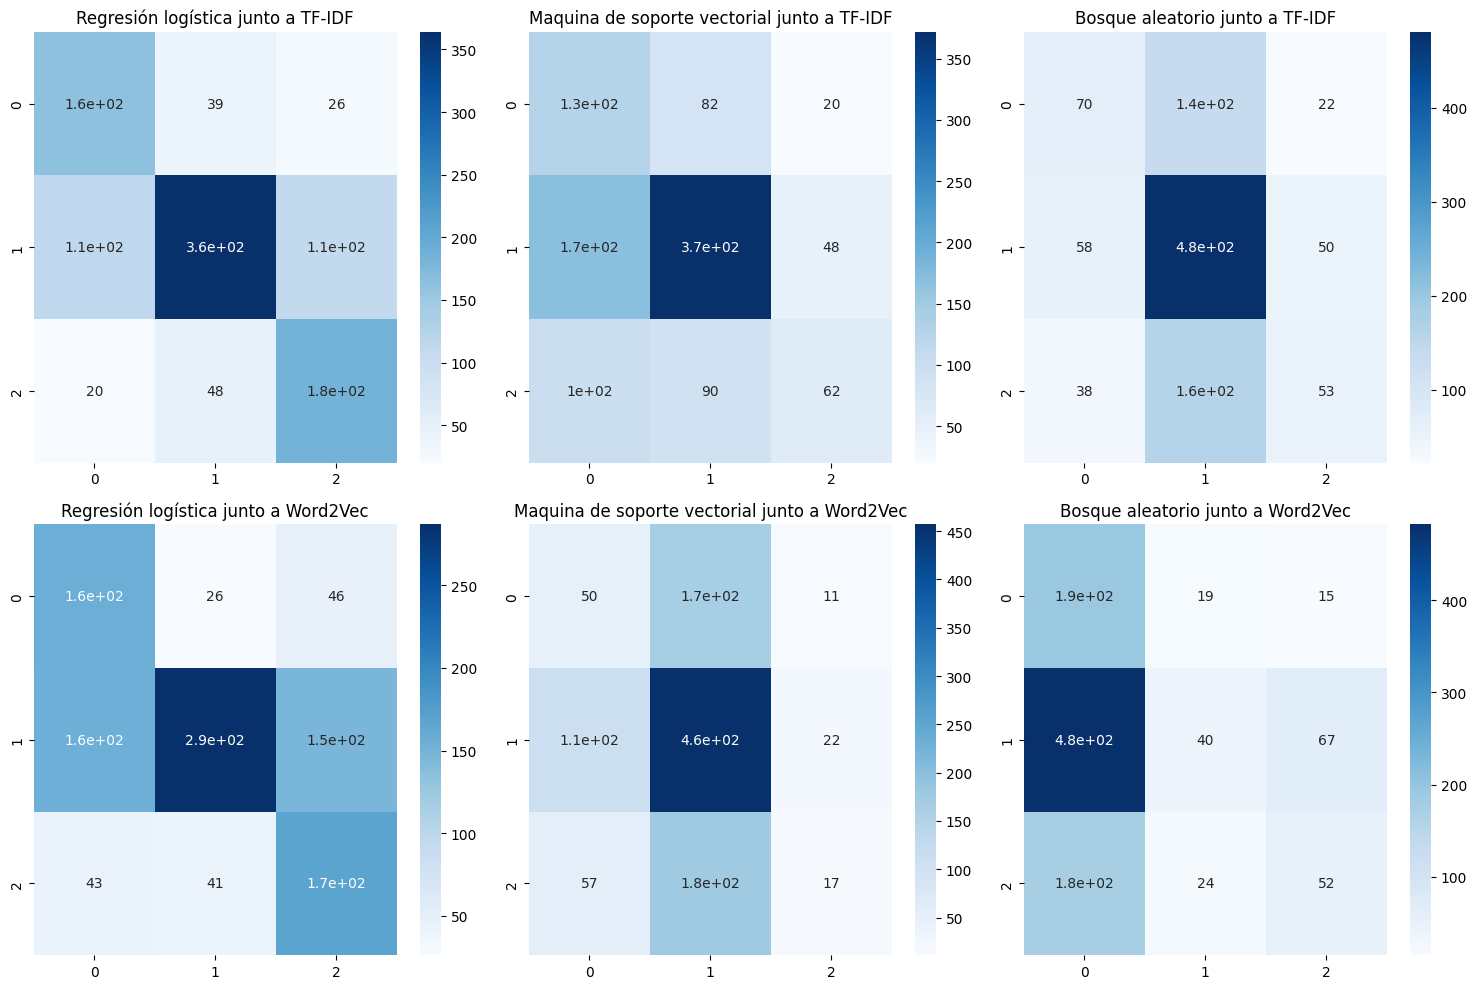

In [ ]:
fig, axes = plt.subplots(2, 3, figsize=(15, 10))

cm = confusion_matrix(y_test, lr_TFIDF_grid_search.predict(X_test))
sns.heatmap(cm, annot=True, cmap='Blues', ax=axes[0,0])
axes[0,0].set_title('Regresión logística junto a TF-IDF')

cm = confusion_matrix(y_test, svm_TFIDF_grid_search.predict(X_test))
sns.heatmap(cm, annot=True, cmap='Blues', ax=axes[0,1])
axes[0,1].set_title('Maquina de soporte vectorial junto a TF-IDF')

cm = confusion_matrix(y_test, rf_TFIDF_grid_search.predict(X_test))
sns.heatmap(cm, annot=True, cmap='Blues', ax=axes[0,2])
axes[0,2].set_title('Bosque aleatorio junto a TF-IDF')

cm = confusion_matrix(y_test, lr_W2V_grid_search.predict(X_test))
sns.heatmap(cm, annot=True, cmap='Blues', ax=axes[1,0])
axes[1,0].set_title('Regresión logística junto a Word2Vec')

cm = confusion_matrix(y_test, rf_W2V_grid_search.predict(X_test))
sns.heatmap(cm, annot=True, cmap='Blues', ax=axes[1,1])
axes[1,1].set_title('Maquina de soporte vectorial junto a Word2Vec')

cm = confusion_matrix(y_test, svm_W2V_grid_search.predict(X_test))
sns.heatmap(cm, annot=True, cmap='Blues', ax=axes[1,2])
axes[1,2].set_title('Bosque aleatorio junto a Word2Vec')

plt.tight_layout()
plt.show()

Un aspecto importante a considerar es la naturaleza de la variable objetivo, que en este caso tiene 3 categorías. Esto implica que, en un escenario aleatorio, se esperaría una precisión del 33.33% (0.3333).

Si bien los tres modelos evaluados —regresión logística, máquinas de soporte vectorial y bosques aleatorios— lograron identificar patrones relevantes en los datos, su desempeño general fue relativamente bajo.

Centrándonos en la matriz de confusión del mejor modelo (regresión logística junto con TF-IDF), se puede evidenciar que la mayoría de errores de clasificación ocurren cerca de la diagonal, señalando la dificultad para discriminar entre categorías cercanas debido a su carácter ordinal. Analizando con detenimiento dicha matriz, se pueden identificar tres grupos, como se observa a continuación.

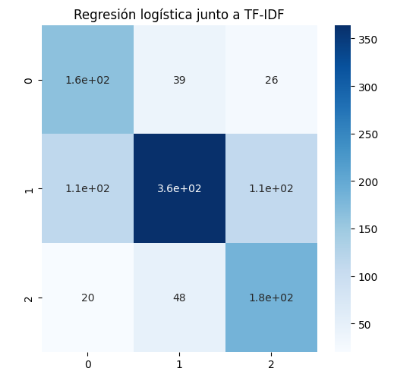

Como la variable objetivo solo tiene tres categorias (positive, neutral y negative), No es necesario realizar una recategorización para mejorar el desempeño de los modelos.

Dado que la regresión logística junto a TF-IDF obtuvo resultados considerablemente superiores a los demás modelos evaluados, se asume la presencia de linealidad en el problema de clasificación. Por lo que únicamente se prueba este modelo en este nuevo contexto.

In [ ]:
pipeline_lr_TFIDF_simplified = Pipeline([('vectorizer', TfidfVectorizer()),
                              ('classifier', LogisticRegression(class_weight="balanced"))])

lr_param_grid = {'vectorizer__max_features': [128,256,512,1024],
                 'classifier__C': [0.01, 0.1, 1, 10]}

print('Ejecutando busqueda de hiperparametros de la regresión logistica ...')
lr_TFIDF_simplified_grid_search = GridSearchCV(pipeline_lr_TFIDF_simplified, lr_param_grid, cv=5, scoring='f1_macro', verbose=1, n_jobs=-1)
lr_TFIDF_simplified_grid_search.fit(X_train, y_train)

print("Regresión logística:")
print(" Mejor combinación de hiperparametros:", lr_TFIDF_simplified_grid_search.best_params_)
print(" rendimiento:", lr_TFIDF_simplified_grid_search.best_score_)

Ejecutando busqueda de hiperparametros de la regresión logistica ...
Fitting 5 folds for each of 16 candidates, totalling 80 fits
Regresión logística:
 Mejor combinación de hiperparametros: {'classifier__C': 1, 'vectorizer__max_features': 1024}
 rendimiento: 0.6469291633319242


Al obtener un macro-F1-score de 0.64 se pudo evidenciar que el modelo extrajo patrones valiosos del conjunto de datos y logro clasificar noticias economicas a partir de sus reseñas.

## **3. Evaluación o Aplicación del modelo**
---

Una vez definido el modelo óptimo, incluyendo sus hiperparámetros ajustados mediante validación cruzada, es esencial evaluar su desempeño en el conjunto de prueba reservado a través de la estrategia *hold-out*. Dado que este conjunto no ha sido utilizado durante el entrenamiento ni en la selección de hiperparámetros, proporciona una medida objetiva del rendimiento del modelo en datos no vistos.

Para realizar un análisis exhaustivo del modelo, no nos limitaremos a observar únicamente la métrica de desempeño designada *F1-score*. Profundizaremos en la evaluación mediante la visualización de la matriz de confusión y el cálculo de métricas asociadas. La matriz de confusión nos permitirá identificar patrones de confusión entre las clases, revelando qué tipos de errores comete el modelo con mayor frecuencia.

A partir de la matriz de confusión, calcularemos métricas adicionales como la precisión, la exhaustividad (*recall*), la especificidad, entre otras. Estas métricas complementarias nos proporcionarán una visión más completa del desempeño del modelo y nos ayudarán a comprender sus fortalezas y debilidades en diferentes aspectos de la clasificación.

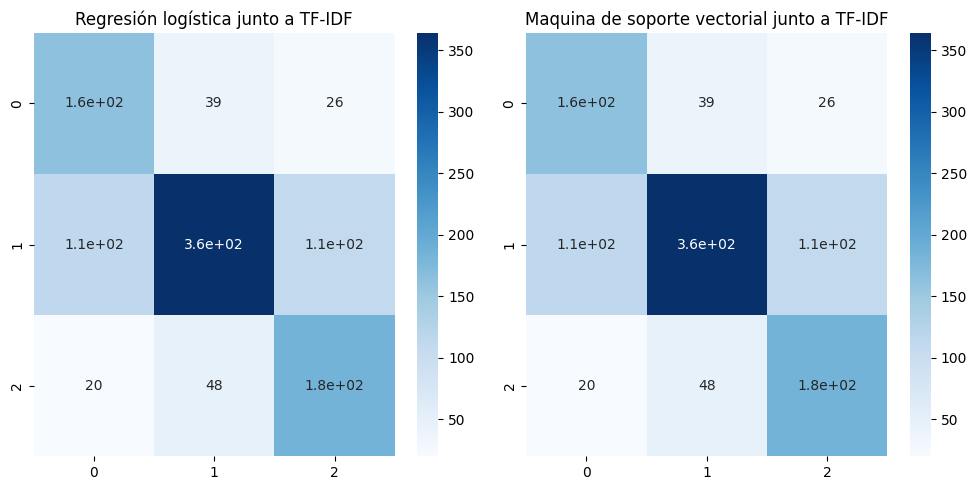

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(10, 5))

cm = confusion_matrix(y_test, lr_TFIDF_grid_search.predict(X_test))
sns.heatmap(cm, annot=True, cmap='Blues', ax=axes[0])
axes[0].set_title('Regresión logística junto a TF-IDF')

cm = confusion_matrix(y_test, lr_TFIDF_simplified_grid_search.predict(X_test))
sns.heatmap(cm, annot=True, cmap='Blues', ax=axes[1])
axes[1].set_title('Maquina de soporte vectorial junto a TF-IDF')

plt.tight_layout()
plt.show()

In [ ]:
print(classification_report(y_test,  lr_TFIDF_simplified_grid_search.predict(X_test)))

              precision    recall  f1-score   support

    negative       0.55      0.71      0.62       228
     neutral       0.81      0.62      0.70       589
    positive       0.57      0.73      0.64       252

    accuracy                           0.67      1069
   macro avg       0.64      0.69      0.65      1069
weighted avg       0.70      0.67      0.67      1069



Los valores de *macro-F1* obtenidos por los modelos se encuentran en un rango relativamente alto, entre 0.62 y 0.70, lo que sugiere un buen rendimiento general en la clasificación. Sin embargo, un análisis más profundo revela que existen áreas de mejora. Teniendo en cuenta nuestra meta la cual es generar un informe general del sentimiento de las personas con respecto a una noticia economica, buscamos un equilibrio entre falsos positivos y falsos negativos por tal razon nuestra metrica clave será *macro-F1*, siguiendo esta clasificación encontramos que la categoria con menor desempeño fue *negative* con 0.62, sin embargo la categoria *positive*, tuvo un desempeño similar de 0.64, y la categoria *neutral* un desempeño superior de 0.70, lo cual indica que se tiene un mejor desempeño analizando el sentimiento de una noticia económica cuando esta es neutral que cuando es negativa o positiva.

A pesar de este desafío, se concluye que la regresión logística en combinación con la técnica de vectorización de texto *TF-IDF* demostró ser la mejor elección de métodos para este problema en particular. Esta configuración capturó de manera efectiva las características relevantes del texto, permitiendo al modelo realizar predicciones con una precisión aceptable en la mayoría de las clases.

El análisis de las matrices de confusión proporciona información valiosa sobre el impacto positivo de la recodificación de las categorías originales. Al comparar las matrices de confusión del modelo entrenado con las categorías recodificadas y el modelo entrenado con la categorización original, se evidencia un incremento significativo en la cantidad de verdaderos positivos, reflejado en el fortalecimiento de la diagonal de la matriz.

Para ilustrar mejor el rendimiento del modelo, a continuación, se presentan algunos casos:

In [ ]:
errores = X_test[y_test !=  lr_TFIDF_simplified_grid_search.predict(X_test)]
aciertos = X_test[y_test ==  lr_TFIDF_simplified_grid_search.predict(X_test)]

error = errores.iloc[0]
acierto = aciertos.iloc[0]

error_prb = lr_TFIDF_simplified_grid_search.predict_proba([error])[0]
acierto_prb = lr_TFIDF_simplified_grid_search.predict_proba([acierto])[0]

print('ERROR:')
error_texto = '\n'.join([' '.join(error.split(' ')[i:i + 10]) for i in range(0, len(error.split(' ')), 10)])
print(error_texto)
print(f'\nClase original: {y_test[y_test !=  lr_TFIDF_simplified_grid_search.predict(X_test)].iloc[0]}')
print(f'Clase recodificada: {y_test[y_test !=  lr_TFIDF_simplified_grid_search.predict(X_test)].iloc[0]}')
print(f'Probabiliadad de pertenencia por clase: {error_prb}')
print('-'*110)

print('\n\nACIERTO:')
acierto_texto = '\n'.join([' '.join(acierto.split(' ')[i:i + 10]) for i in range(0, len(acierto.split(' ')), 10)])
print(acierto_texto)
print(f'\nClase original: {y_test[y_test ==  lr_TFIDF_simplified_grid_search.predict(X_test)].iloc[0]}')
print(f'Clase recodificada: {y_test[y_test ==  lr_TFIDF_simplified_grid_search.predict(X_test)].iloc[0]}')
print(f'Probabiliadad de pertenencia por clase: {acierto_prb}')


ERROR:
acción recurso natural cotizar actualmente valoración atractivo comparación acción global
general servir cobertura inflación explicar firma

Clase original: positive
Clase recodificada: positive
Probabiliadad de pertenencia por clase: [0.16763733 0.60113385 0.23122882]
--------------------------------------------------------------------------------------------------------------


ACIERTO:
num teléfono web facturación num num millón nş empleado álvaropresidentesixt
rent sede social canal sant jordi num local num

Clase original: neutral
Clase recodificada: neutral
Probabiliadad de pertenencia por clase: [0.00946036 0.98375785 0.00678178]


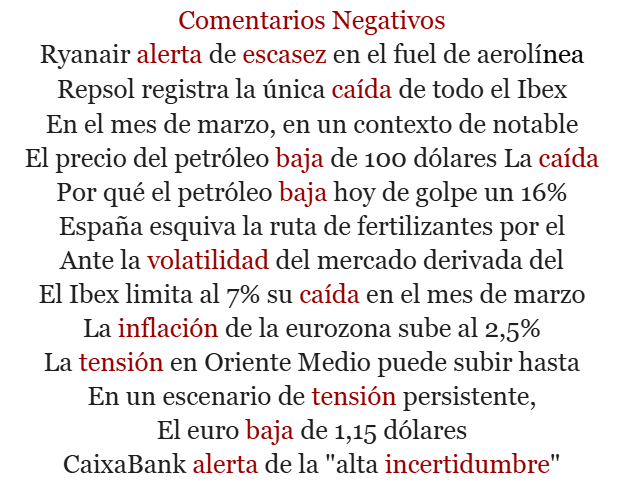

## **Referencias**
---
[1] Kenpache. *Multilingual Financial Sentiment* (dataset). Hugging Face. https://huggingface.co/datasets/Kenpache/multilingual-financial-sentiment

[2] Explosion AI. *spaCy: Industrial-strength Natural Language Processing*. https://spacy.io/

[3] spacy-langdetect. https://github.com/Abhijit-2592/spacy-langdetect

[4] Textstat: índice de legibilidad de Fernández-Huerta. https://www.spanishreadability.com/fernandez-huerta-readability-index

[5] Coeficiente de correlación de Spearman. https://www.sciencedirect.com/topics/mathematics/spearman-rank-correlation-coefficient

[6] V de Cramér (asociación entre variables categóricas). https://en.wikipedia.org/wiki/Cram%C3%A9r%27s_V

[7] Correlación de Pearson. https://www.sciencedirect.com/topics/computer-science/pearson-correlation

## **Créditos**

* **Profesores:** [Felipe Restrepo Calle](https://ferestrepoca.github.io/), [Elizabeth León Guzman](https://midas.unal.edu.co/)
* **Asistentes docentes:**
    - [Juan Sebastián Malagón Torres](https://co.linkedin.com/in/juan-sebastian-malag%C3%B3n-torres-86039a164).
* **Diseño de imágenes:**
    - [Sebastián Daniel Moreno Martinez](http://www.linkedin.com/in/sm-xwx).
* **Coordinador de virtualización:**
    - [Edder Hernández Forero](https://www.linkedin.com/in/edder-hernandez-forero-28aa8b207/).

**Universidad Nacional de Colombia** - *Facultad de Ingeniería*